In [1]:
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

SCRATCH_DIR = Path("/home/sd2402/torquato-scratch-sd2402/")

DIR_1 = SCRATCH_DIR.joinpath("anirban_equiluminous/data/p0/patterns")
DIR_2 = SCRATCH_DIR.joinpath("anirban_equiluminous/data/p5/patterns")
DIR_3 = SCRATCH_DIR.joinpath("anirban_equiluminous/data/p10/patterns")
DIR_4 = SCRATCH_DIR.joinpath("anirban_equiluminous/data/p20/patterns")

In [2]:
def readfile(ifile: str):
    with open(ifile, "r") as f:
        yield from f
        
def read_xd_data(ifile: str, idx: slice=slice(0, -1, 1), delim: str=",") -> np.array:
    header = ""
    Z = []
    for line in readfile(ifile):
        if "#" in line:
            header += line
            continue
        L = line.strip("\n").split(delim)
        res = [float(a) for a in L[:]]
        Z.append(res)
    return np.asarray(Z)

def read_cco(inpfile: str) -> tuple:
    """
    Read data from CCO, taking advantage of fixed file setup
    Returns
        d               = system dimensionality
        num_particles   = number of particles
        lattice_vectors = primitive lattice vectors of 3D system
        coordinates     = positions of all individual spheres
    """
    lattice_vectors = []
    coordinates = []
    
    with open(inpfile, "r") as f:
        lines = f.readlines()
        d = int(lines[0].strip("\n"))
        n_particles = len(lines) - (d + 1) # d counts number of vectors, -1 for dimension in the first line
        for i in range(1, d+1): # Get all basis vectors
            basis_vector = lines[i].strip("\n").split()
            lattice_vectors.append([float(a) for a in basis_vector[:d]])
        for j in range(d+1, len(lines)): # Get all coordinates
            coord = lines[j].strip("\n").split()
            coordinates.append([float(a) for a in coord[:d]])

    return d, n_particles, np.array(lattice_vectors), np.array(coordinates)

def parallelipiped_volume(basis_vectors: np.array) -> float:
    return np.abs(np.linalg.det(basis_vectors))

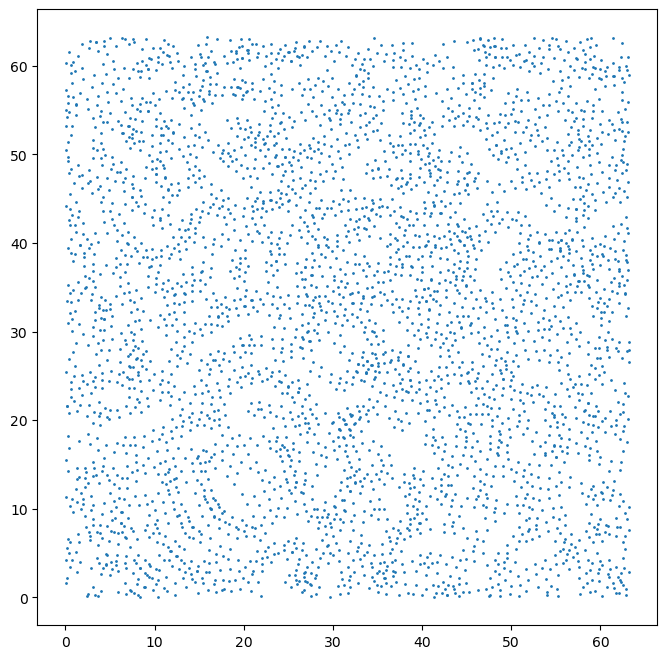

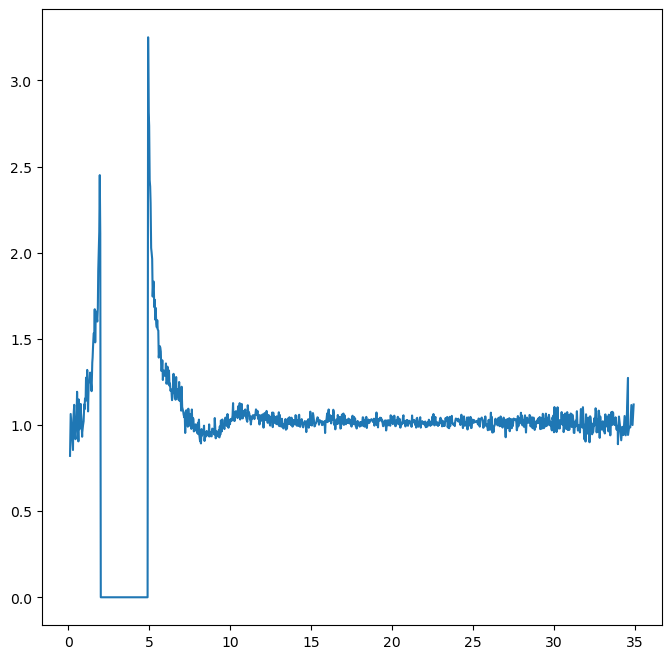

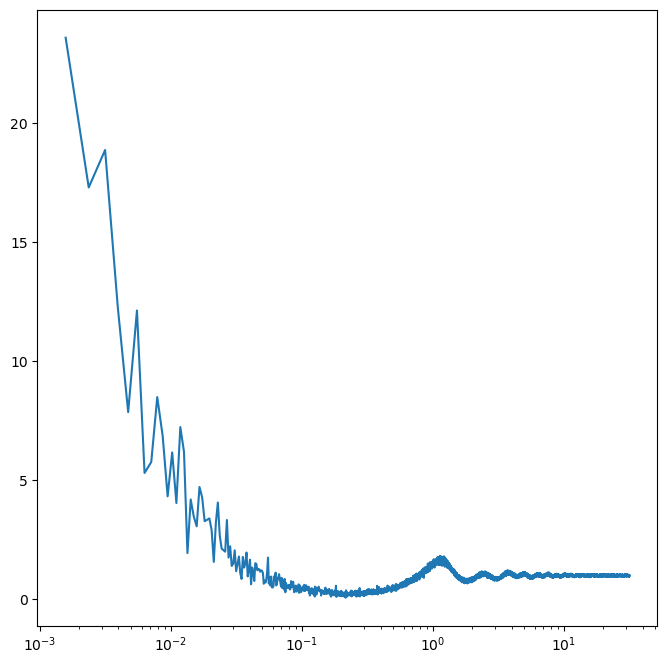

In [3]:

DIR = DIR_4

data = DIR.joinpath("ccoptimization_Success__0002.txt")
stfc = DIR.joinpath("sf_bin.txt")
pair = DIR.joinpath("g2_res.txt")

dimension, n_particles, lv, coords = read_cco(data)
sf = read_xd_data(stfc)
g2 = read_xd_data(pair)

# ----- point pattern -----
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(*coords.T, s=1)

# ----- structure factor -----
fig, ax = plt.subplots(figsize=(8,8))
ax.plot(sf[:, -2], sf[:, -1])

# ----- pair correlation function -----
fig, ax = plt.subplots(figsize=(8,8))
ax.set_xscale("log")
ax.plot(g2[:, -2], g2[:, -1])

# PAIR STATISTICS

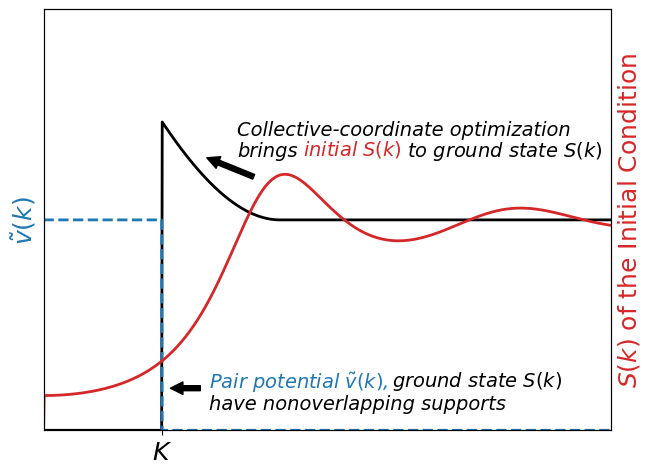

In [4]:
def py(k: float, eta: float, rho: float) -> float:
    # derived
    sigma = np.cbrt(3 * eta / 4 / np.pi / rho)
    q = k * sigma
    a1 = (1 + 2 * eta)**2 / (1 - eta)**4
    a2 = - (1 + eta / 2)**2 / (1 - eta)**4

    # direct correlation function
    t1 = a1 * (np.sin(q) - q * np.cos(q))
    t2 = 6 * eta * a2 * (2 * q * np.sin(q) + (2 - q**2) * np.cos(q) - 2) / q
    t3 = eta * a1 * (4 * q * (q**2 - 6) * np.sin(q) - (24 - 12 * q**2 + q**4) * np.cos(q) + 24) / 2 / q**3

    ck = -4 * np.pi * (t1 + t2 + t3) / q**3

    # structure factor
    return 1 + rho * ck / (1 - rho * ck)

# ----- metadata -----
fontsize = 18
exclusion_radius = 5.0
packing_fraction = 0.3
number_density = 0.3

# ----- figure -----
fig, ax = plt.subplots()
fig.tight_layout()  # otherwise the right y-label is slightly clipped
ax2 = ax.twinx()

ax.set_xlim(1e-4, 24); ax.set_xticks([])
ax.set_ylim(0, 2.0); ax.set_yticks([])
ax2.set_ylim(0, 2.0); ax2.set_yticks([])

ax.set_xticks([exclusion_radius], [r"$K$"], fontsize=fontsize)

ax.set_xlabel(r"", fontsize=fontsize)
ax.set_ylabel(r"$\tilde{v}(k)$", color="tab:blue", fontsize=fontsize)
ax2.set_ylabel(r"$S(k)$ of the Initial Condition", color="tab:red", fontsize=fontsize)

# ----- series -----
x_series = np.linspace(*ax.get_xlim(), 1000)
pair_potential = np.heaviside(exclusion_radius - x_series, 0.0)
structure_factor = py(x_series, packing_fraction, number_density)
# shu_ground_state = np.heaviside(x_series - exclusion_radius, 0.0) * py(x_series, packing_fraction, number_density)

intersection = np.heaviside(2 * exclusion_radius - x_series, 0.0) * (1 - 3 * x_series / exclusion_radius / 4 + np.power(x_series / exclusion_radius, 3) / 16)
shu_ground_state = np.heaviside(x_series - exclusion_radius, 0.0) * (1 + 5 * packing_fraction * intersection)

# ----- plotting -----
ax.plot(x_series, shu_ground_state, color="black", lw=2, ls="-")
ax.plot(x_series, pair_potential, color="tab:blue", lw=2, ls="--")
ax2.plot(x_series, structure_factor, color="tab:red", lw=2, ls="-")

# ----- annotation -----
ax.annotate(
    "", xytext=(9, 1.2), xy=(6.8, 1.3),
    transform=ax.axes, ha="center", fontsize=fontsize,
    arrowprops={"arrowstyle": "simple", "facecolor": "black"}
)
ax.annotate(
    "Collective-coordinate optimization", xy=(8.2, 1.4),
    transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic"
)
ax.annotate(
    "brings", xy=(8.2, 1.3),
    transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic"
)
ax.annotate(
    r"initial $S(k)$", xy=(10.99, 1.31),
    transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic", color="tab:red"
)
ax.annotate(
    r"to ground state $S(k)$", xy=(15.4, 1.3),
    transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic"
)

ax.annotate(
    "", xytext=(1.35 * exclusion_radius, 0.2), xy=(1.05 * exclusion_radius, 0.2),
    transform=ax.axes, ha="center", fontsize=fontsize,
    arrowprops={"arrowstyle": "simple", "facecolor": "black"}
)
# ax.annotate(
#     r"Supports of", xy=(1.4 * exclusion_radius, 0.2), 
#     transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic"
# )
ax.annotate(
    r"Pair potential $\tilde{v}(k)$,", xy=(1.4 * exclusion_radius, 0.2), 
    transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic", color="tab:blue"
)
ax.annotate(
    r"ground state $S(k)$", xy=(2.95 * exclusion_radius, 0.21),
    transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic", #color="tab:red"
)
ax.annotate(
    r"have nonoverlapping supports", xy=(1.4 * exclusion_radius, 0.1),
    transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic"
)

plt.savefig("./stealthy_example.png", dpi=1024)


/tmp/ipykernel_3362908/3710695925.py:10: RuntimeWarning: divide by zero encountered in scalar divide
  vr = lambda r: (exclusion_radius / 2 / np.pi / r)**(dimension / 2) * scipy.special.jv(dimension / 2, exclusion_radius * r)
/tmp/ipykernel_3362908/3710695925.py:10: RuntimeWarning: invalid value encountered in scalar multiply
  vr = lambda r: (exclusion_radius / 2 / np.pi / r)**(dimension / 2) * scipy.special.jv(dimension / 2, exclusion_radius * r)


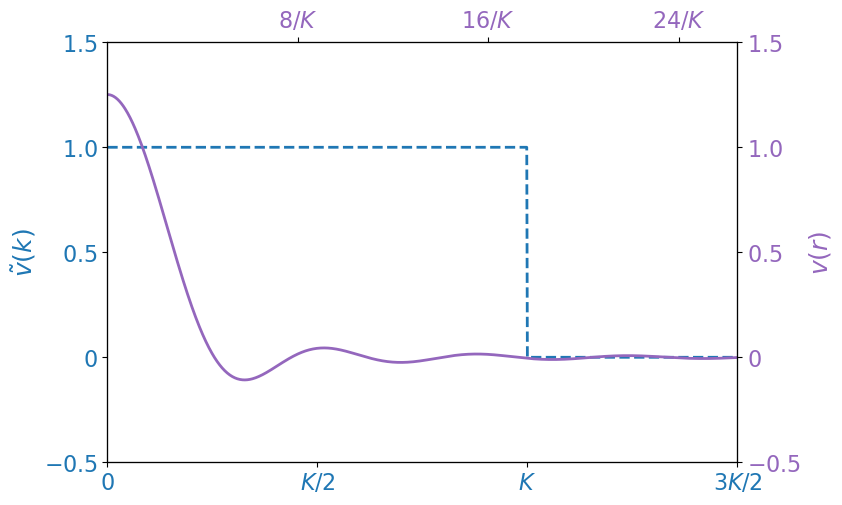

In [145]:
import scipy

# ----- metadata -----
fontsize = 18
dimension = 3
exclusion_radius = 4.2
packing_fraction = 0.3
number_density = 0.3

vr = lambda r: (exclusion_radius / 2 / np.pi / r)**(dimension / 2) * scipy.special.jv(dimension / 2, exclusion_radius * r)

# ----- figure -----
fig, ax = plt.subplots(figsize=(9, 6))
# fig.tight_layout()  # otherwise the right y-label is slightly clipped
plt.subplots_adjust(left=0.15, right=0.85, bottom=0.15, top=0.85)
ax2 = ax.twinx()
ax3 = ax.twiny()

xlabels = ["0", r"$K/2$", r"$K$", r"$3K/2$"]
xticks = [0, exclusion_radius / 2, exclusion_radius, 3 * exclusion_radius / 2]
ax.set_xlim(1e-5, 1.5 * exclusion_radius)
ax.set_xticks(xticks, labels=xlabels, fontsize=fontsize-2, color="tab:blue")
ax3.set_xlim(*ax.get_xlim())
ax3.set_xticks(
    [8 / exclusion_radius, 16 / exclusion_radius, 24 / exclusion_radius],
    labels=[r"$8/K$", r"$16/K$", r"$24/K$"],
    fontsize=fontsize-2, color="tab:purple"
)

yticks = [-0.5, 0, 0.5, 1.0, 1.5]
ylabels = [r"$-0.5$", r"$0$", r"$0.5$", r"$1.0$", r"$1.5$"]
ax.set_ylim(-0.5, 1.5)
ax.set_yticks(yticks, ylabels, fontsize=fontsize-2, color="tab:blue")
ax2.set_ylim(*ax.get_ylim())
ax2.set_yticks(yticks, ylabels, fontsize=fontsize-2, color="tab:purple")

# ax.set_xlabel(r"$k$", fontsize=fontsize)
ax.set_xlabel("", fontsize=fontsize)
ax2.set_ylabel(r"$v(r)$", color="tab:purple", fontsize=fontsize)
ax.set_ylabel(r"$\tilde{v}(k)$", color="tab:blue", fontsize=fontsize)

# ----- series -----
k_series = np.linspace(*ax.get_xlim(), 1000)
r_series = np.linspace(*ax3.get_xlim(), 1000)

pair_potential = np.heaviside(exclusion_radius - k_series, 0.0)
real_space_potential = np.asarray([vr(r) for r in r_series])

# ----- plotting -----
ax.plot(k_series, pair_potential, color="tab:blue", lw=2, ls="--")
ax.plot(r_series, real_space_potential, color="tab:purple", lw=2, ls="-")

# ----- annotation -----
# ax.annotate(
#     "", xytext=(9, 1.2), xy=(6.8, 1.3),
#     transform=ax.axes, ha="center", fontsize=fontsize,
#     arrowprops={"arrowstyle": "simple", "facecolor": "black"}
# )
# ax.annotate(
#     "Collective-coordinate optimization", xy=(8.2, 1.4),
#     transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic"
# )
# ax.annotate(
#     "brings", xy=(8.2, 1.3),
#     transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic"
# )
# ax.annotate(
#     r"initial $S(k)$", xy=(10.99, 1.31),
#     transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic", color="tab:red"
# )
# ax.annotate(
#     r"to ground state $S(k)$", xy=(15.4, 1.3),
#     transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic"
# )

# ax.annotate(
#     "", xytext=(1.35 * exclusion_radius, 0.2), xy=(1.05 * exclusion_radius, 0.2),
#     transform=ax.axes, ha="center", fontsize=fontsize,
#     arrowprops={"arrowstyle": "simple", "facecolor": "black"}
# )
# ax.annotate(
#     r"Supports of", xy=(1.4 * exclusion_radius, 0.2), 
#     transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic"
# )
# ax.annotate(
#     r"Pair potential $\tilde{v}(k)$,", xy=(1.4 * exclusion_radius, 0.2), 
#     transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic", color="tab:blue"
# )
# ax.annotate(
#     r"ground state $S(k)$", xy=(2.95 * exclusion_radius, 0.21),
#     transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic", #color="tab:red"
# )
# ax.annotate(
#     r"have nonoverlapping supports", xy=(1.4 * exclusion_radius, 0.1),
#     transform=ax.axes, ha="left", fontsize=fontsize - 4, fontstyle="italic"
# )

plt.savefig("./stealthy_example.png", dpi=1024)
